Null Values:
 Age            0
Sex            0
BP             0
Cholesterol    0
Na_to_K        0
Drug           0
dtype: int64
Age           -0.004828
Sex           -0.098573
BP             0.372868
Cholesterol    0.055629
Na_to_K        0.589120
Drug_num       1.000000
Name: Drug_num, dtype: float64


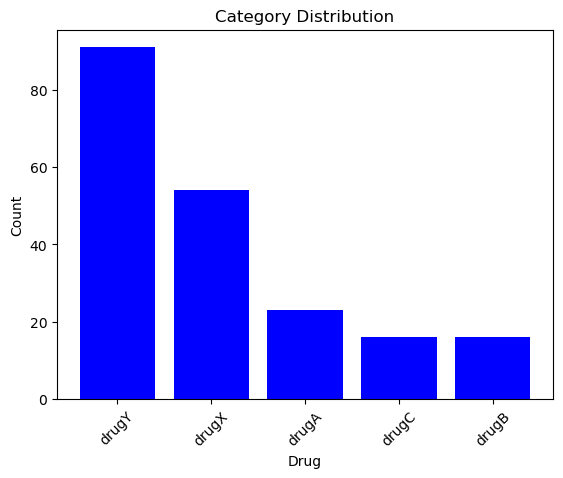

Decision tree score, 0.983


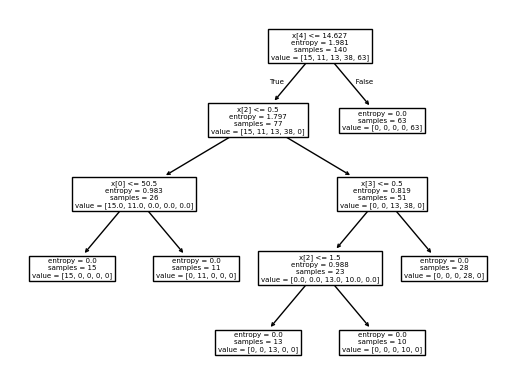

Age              int64
Sex              int64
BP               int64
Cholesterol      int64
Na_to_K        float64
Drug               str
Drug_num         int64
dtype: object


In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split 
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn import metrics

path= 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%203/data/drug200.csv'
my_data=pd.read_csv(path)
#4 out of 6 features are categorical which have to get converted to numbers because sklearn models do math on features & u can't do math on words
label_encoder=LabelEncoder()
my_data['Sex']=label_encoder.fit_transform(my_data['Sex'])
my_data["BP"]=label_encoder.fit_transform(my_data['BP'])
my_data['Cholesterol']=label_encoder.fit_transform(my_data['Cholesterol'])
print("Null Values:\n",my_data.isnull().sum())# looking for null values in my dataset which I don't have any
# Na_to_K --> 0.589120 has the strongest relationship with the target, meaning the higher this ration the more likely to be prescribed drugY:4
custom_map={'drugA':0,'drugB':1,'drugC':2,'drugX':3,'drugY':4}
my_data['Drug_num']=my_data['Drug'].map(custom_map) 
print(my_data.drop(['Drug'],axis=1).corr()['Drug_num']) #dropping the Drug column bc .corr() is a math function and Drug is str 

category_count=my_data['Drug'].value_counts()
plt.bar(category_count.index,category_count.values,color='blue')

plt.xlabel('Drug')
plt.ylabel('Count')
plt.title('Category Distribution')
plt.xticks(rotation=45)  # Rotate labels for better readability if needed
plt.show() 
Y=my_data['Drug']
X=my_data.drop(['Drug','Drug_num'], axis=1)
X_trainset, X_testset, y_trainset, y_testset = train_test_split(X, Y, test_size=0.3, random_state=32)

Drug_tree=DecisionTreeClassifier(criterion='entropy',max_depth=4) # max_depth indicates the number of questions that will be asked 
Drug_tree.fit(X_trainset,y_trainset)

tree_prediction=Drug_tree.predict(X_testset)
print(f"Decision tree score, {metrics.accuracy_score(y_testset,tree_prediction):.3f}")
plot_tree(Drug_tree)
plt.show() 
print(my_data.dtypes) 
# The thresholds on the tree are the midpoints : X[4]<= 14.027 means if Na_to_K is more than that number---> false and the prescribed drug is Y ,[0,0,0,64] 
# The Gini(faster)/Entropy(more eager) scores are impurity score : how mixed up a node on different scales 
